# BT4012 Kaggle 2026 — Illicit Bitcoin Transaction Detection

Task: Predict P(illicit) for Bitcoin transactions in future time steps (36–49), given labelled transactions from steps 1–35, 165 anonymised features per transaction, and the transaction graph

Final submissions (selected on Kaggle)

| File | Model | Public LB |
|---|---|---|
| `final_sub23_stack_ensemble8.csv` | Rank-average of 8 graph-stacked models (Section 7.4) | 0.95985 |
| `final_sub14_graphstack.csv` | Single graph-stacked model on Model A (Section 7.3) | 0.95903 |

- Model A: LightGBM, 165 raw features + labelled-neighbour graph features (Section 3.2), 1,000 trees
- Model B: LightGBM, 165 raw features + degree + neighbour-mean features over all featured neighbours (Section 3.1)
- Graph stacking: a first-stage model which scores each transaction; a second-stage model then receives each transaction's features and the predicted scores of its graph neighbours (mean / max / sum over senders and receivers); Training-set neighbour scores come from out-of-fold models that never saw that time step, so the features are built the same way in train and test

Notebook outline
1. Setup & data loading
2. EDA: label imbalance over time, and how the test set was constructed
3. Feature engineering: two families of graph features
4. Validation design: temporal folds, and how far they track the leaderboard
5. Feature-set ablation
6. Single-stage models (Model A, Model B)
7. Graph stacking: validation and final submissions
8. Post-step-43 analysis (the dark-market shutdown)
9. Experiment log (all Kaggle submissions, including negative results)

To regenerate only the two submission files, set `RUN_ABLATION = False` and `RUN_STACK_VALIDATION = False` in the first code cell, which then skip validation experiments and do not change the predictions

## 1. Setup & data loading

In [ ]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from scipy.stats import rankdata, spearmanr
from sklearn.metrics import roc_auc_score

SEED = 42
DATA_DIR = Path("data")            # train.csv, test.csv, txs_edgelist.csv, sample_submission.csv
CACHE_DIR = Path("cache")          # parquet copies + engineered features (git-ignored, auto-created)
SUB_DIR = Path("submissions")      # output CSVs (git-ignored)
for d in (CACHE_DIR, SUB_DIR):
    d.mkdir(exist_ok=True)

RUN_ABLATION = True                # Section 5: feature-set ablation over 3 folds x 3 seeds
RUN_STACK_VALIDATION = True        # Section 7.2: stacking vs single-stage on fold F3
STACK_SEEDS = range(3)             # seeds averaged in each final stacked model (as submitted)

# LightGBM settings shared by every model in this notebook
LGB_PARAMS = dict(
    n_estimators=500, learning_rate=0.03, num_leaves=31,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.5,
    random_state=SEED, verbose=-1,
)
pd.set_option("display.max_columns", 60)

In [ ]:
def load_csv_cached(name: str) -> pd.DataFrame:
    """Read data/<name>.csv once, then reuse a parquet copy (much faster on reruns)."""
    pq = CACHE_DIR / f"{name}.parquet"
    if pq.exists():
        return pd.read_parquet(pq)
    df = pd.read_csv(DATA_DIR / f"{name}.csv")
    df.to_parquet(pq)
    return df

t0 = time.time()
train = load_csv_cached("train")
test = load_csv_cached("test")
edges = pd.read_csv(DATA_DIR / "txs_edgelist.csv")
sample_sub = pd.read_csv(DATA_DIR / "sample_submission.csv")
print(f"loaded in {time.time() - t0:.1f}s")

FEATS = [c for c in train.columns if c.startswith("feat_")]
LOCAL = FEATS[:93]   # assumed local block (aggregated features follow); used for neighbour aggregation
assert FEATS == [c for c in test.columns if c.startswith("feat_")]
print("train", train.shape, "| test", test.shape, "| edges", edges.shape, "| features", len(FEATS))

loaded in 0.4s
train (141772, 168) | test (15329, 168) | edges (234355, 2) | features 165


## 2. EDA

In [ ]:
# label: 1 = illicit, 0 = licit, NaN = unknown
print(train["label"].value_counts(dropna=False))
print("train steps", train.time_step.min(), "to", train.time_step.max(),
      "| test steps", test.time_step.min(), "to", test.time_step.max())
print("missing feature values:", int(train[FEATS].isna().sum().sum()), "(train),",
      int(test[FEATS].isna().sum().sum()), "(test)")

# labelled training rows only, row order is kept fixed (train order) for reproducibility
lab = train[train.label.notna()].copy()
lab["label"] = lab["label"].astype(int)

label
NaN    110537
0.0     27591
1.0      3644
Name: count, dtype: int64
train steps 1 to 35 | test steps 36 to 49
missing feature values: 0 (train), 0 (test)


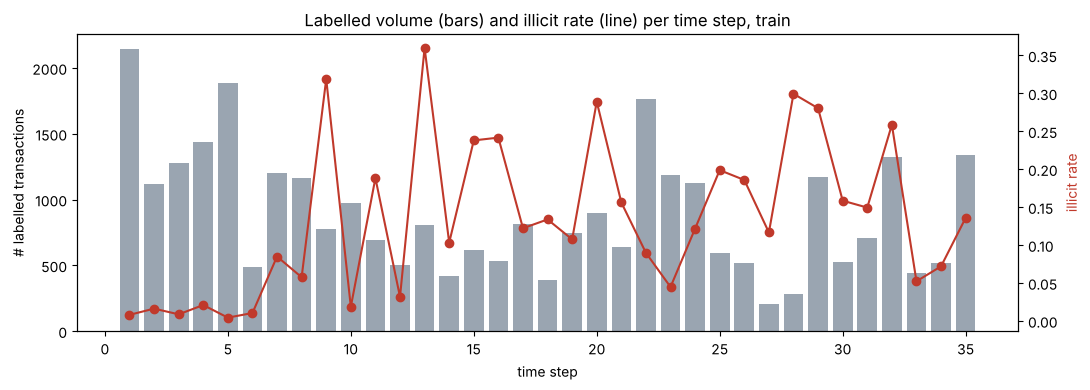

time_step,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35
n,2147.000,1117.000,1279.000,1440.000,1882.000,485.00,1203.000,1165.000,778.000,972.000,696.000,506.000,809.00,417.000,618.000,530.000,811.000,389.000,745.000,900.000,641.000,1763.00,1187.000,1126.000,594.000,517.000,206.000,284.000,1174.00,524.000,710.000,1323.000,441.000,515.000,1341.000
illicit,17.000,18.000,11.000,30.000,8.000,5.00,102.000,67.000,248.000,18.000,131.000,16.000,291.00,43.000,147.000,128.000,99.000,52.000,80.000,260.000,100.000,158.00,53.000,137.000,118.000,96.000,24.000,85.000,329.00,83.000,106.000,342.000,23.000,37.000,182.000
rate,0.008,0.016,0.009,0.021,0.004,0.01,0.085,0.058,0.319,0.019,0.188,0.032,0.36,0.103,0.238,0.242,0.122,0.134,0.107,0.289,0.156,0.09,0.045,0.122,0.199,0.186,0.117,0.299,0.28,0.158,0.149,0.259,0.052,0.072,0.136
unknown,5733.000,3427.000,5342.000,4253.000,4921.000,3843.00,4845.000,3292.000,4218.000,5755.000,3600.000,1541.000,3719.00,1605.000,3021.000,2445.000,2574.000,1587.000,2761.000,3391.000,2896.000,4131.00,2978.000,3466.000,1720.000,2006.000,883.000,1369.000,3101.00,1959.000,2106.000,3202.000,2710.000,1971.000,4166.000


In [4]:
per_step = lab.groupby("time_step")["label"].agg(n="size", illicit="sum", rate="mean")
per_step["unknown"] = train[train.label.isna()].groupby("time_step").size()

fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(per_step.index, per_step["n"], color="#9aa5b1")
ax1.set_xlabel("time step"); ax1.set_ylabel("# labelled transactions")
ax2 = ax1.twinx()
ax2.plot(per_step.index, per_step["rate"], color="#c0392b", marker="o")
ax2.set_ylabel("illicit rate", color="#c0392b")
ax1.set_title("Labelled volume (bars) and illicit rate (line) per time step, train")
fig.tight_layout(); plt.show()
per_step.T.round(3)

In [ ]:
# test.csv contains every labelled transaction in steps 36-49
# unknown transactions in those steps appear only in the edge list and have no feature rows
featured = pd.concat([train[["txId", "time_step"]], test[["txId", "time_step"]]]).set_index("txId")["time_step"]
graph_nodes = pd.Index(pd.unique(edges[["txId1", "txId2"]].values.ravel()))
print("nodes with features:", len(featured), "| nodes in graph:", len(graph_nodes))
print("labelled train rows + test rows =", len(lab), "+", len(test), "=", len(lab) + len(test),
      "(the original Elliptic dataset has 46,564 labelled transactions)")

s1, s2 = featured.reindex(edges.txId1).values, featured.reindex(edges.txId2).values
both = ~np.isnan(s1) & ~np.isnan(s2)
print(f"edges with both endpoints featured: {both.mean():.1%}")
print(f"edges inside a single time step:     {(s1[both] == s2[both]).mean():.1%}")
print("time steps of edges touching a featureless node:",
      sorted(int(x) for x in pd.Series(np.where(np.isnan(s1), s2, s1)[~both]).dropna().unique()))

nodes with features: 157101 | nodes in graph: 203769
labelled train rows + test rows = 31235 + 15329 = 46564 (the original Elliptic dataset has 46,564 labelled transactions)
edges with both endpoints featured: 75.1%
edges inside a single time step:     100.0%
time steps of edges touching a featureless node: [36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49]


- illicit rate varies a lot by step (under 1% to 36%), so validation must be with respect to time
- every edge stays inside one time step, so neighbourhoods dont cross the train/test boundary
- in steps 36–49, featureless means unlabelled, so "is this neighbour labelled?" is known for every node in both train and test, and means the same thing in both
- neighbour aggregates built over "all featured neighbours" (Section 3.1) are not consistent: in train they include unlabelled neighbours, in test they cannot

## 3. Graph feature engineering

### 3.1 version 1: degree + neighbour means over all featured neighbours (used by Model B)


In [ ]:
# degree + mean of `agg_cols` over in-/out-neighbours that have feature rows
# in train, 'featured' includes unlabelled train transactions
# but in test it does not
def build_graph_features_v1(train, test, edges, agg_cols):
    allx = pd.concat([train[["txId"] + agg_cols], test[["txId"] + agg_cols]]).set_index("txId")
    out = pd.DataFrame(index=allx.index)
    out["in_deg"] = edges.txId2.value_counts().reindex(out.index).fillna(0)
    out["out_deg"] = edges.txId1.value_counts().reindex(out.index).fillna(0)
    has1, has2 = edges.txId1.isin(allx.index), edges.txId2.isin(allx.index)
    e = edges[has1 & has2]
    in_mean = allx.loc[e.txId1].set_axis(e.txId2.values).groupby(level=0).mean()   # mean over senders
    out_mean = allx.loc[e.txId2].set_axis(e.txId1.values).groupby(level=0).mean()  # mean over receivers
    return out.join(in_mean.add_prefix("nbr_in_mean_")).join(out_mean.add_prefix("nbr_out_mean_"))

p = CACHE_DIR / "graph_feats_v1.parquet"
if p.exists():
    g1 = pd.read_parquet(p)
else:
    t0 = time.time(); g1 = build_graph_features_v1(train, test, edges, LOCAL); g1.to_parquet(p)
    print(f"v1 built in {time.time() - t0:.1f}s")
DEG = ["in_deg", "out_deg"]
NBR_V1 = [c for c in g1.columns if c.startswith("nbr_")]
print("v1 features:", g1.shape[1])

v1 features: 188


### 3.2 version 2: labelled-neighbour features (used by Model A)
for every labelled transaction (train or test):
- nL_in, nL_out, nU_in, nU_out: number of labelled / unlabelled senders and receivers; totals nL, nU, and fracL = share of neighbours that are labelled
- Lmean_in_*, Lmean_out_*: mean of the 93 local features over only labelled neighbours

In [7]:
def build_graph_features_v2(lab, test, edges, feats, agg_cols):
    labelled = pd.concat([lab[["txId"] + feats], test[["txId"] + feats]]).set_index("txId")
    nodes = pd.unique(edges[["txId1", "txId2"]].values.ravel())
    status = pd.Series("U", index=nodes)
    status[status.index.isin(labelled.index)] = "L"
    e = edges.assign(s1=status.reindex(edges.txId1).values, s2=status.reindex(edges.txId2).values)

    G = pd.DataFrame(index=labelled.index)
    # direction -> (node being described, its neighbour, the neighbour's status column)
    for nm, (tgt, src, ss) in {"in": ("txId2", "txId1", "s1"), "out": ("txId1", "txId2", "s2")}.items():
        for s in "LU":
            G[f"n{s}_{nm}"] = e[e[ss] == s][tgt].value_counts().reindex(G.index).fillna(0)
        el = e[(e[ss] == "L") & e[tgt].isin(G.index)]
        nb = labelled.loc[el[src].values, agg_cols].set_axis(el[tgt].values)
        G = G.join(nb.groupby(level=0).mean().add_prefix(f"Lmean_{nm}_"))
    G["nL"] = G.nL_in + G.nL_out
    G["nU"] = G.nU_in + G.nU_out
    G["fracL"] = G.nL / (G.nL + G.nU).replace(0, np.nan)
    return G

p = CACHE_DIR / "graph_feats_v2.parquet"
if p.exists():
    g2 = pd.read_parquet(p)
else:
    t0 = time.time(); g2 = build_graph_features_v2(lab, test, edges, FEATS, LOCAL); g2.to_parquet(p)
    print(f"v2 built in {time.time() - t0:.1f}s")
CNT = ["nL_in", "nL_out", "nU_in", "nU_out", "nL", "nU", "fracL"]
LMEAN = [c for c in g2.columns if c.startswith("Lmean_")]
print("v2 features:", g2.shape[1])

v2 features: 193


In [ ]:
lab = lab.join(g1, on="txId").join(g2, on="txId").copy()
test_full = test.join(g1, on="txId").join(g2, on="txId").copy()
# transactions with no labelled neighbour are about 3x more likely to be illicit
lab.assign(has_labelled_neighbour=lab.nL > 0).groupby("has_labelled_neighbour")["label"].agg(n="size", illicit_rate="mean")

,n,illicit_rate
has_labelled_neighbour,,
False,6799,0.244154
True,24436,0.081192


In [9]:
FEATURE_SETS = {
    "raw_165":          FEATS,
    "raw+v1 (Model B)": FEATS + DEG + NBR_V1,
    "raw+v2 (Model A)": FEATS + CNT + LMEAN,
}

## 4. Validation design
test set is future time steps, so every fold trains on earlier steps and validates on later steps

| Fold | Train steps | Validate steps |
|---|---|---|
| F1 | 1–14 | 15–20 |
| F2 | 1–20 | 21–28 |
| F3 (recent) | 1–28 | 29–35 |

F2 initially looked like the best proxy because its AUC (~0.95) matched the public leaderboard, but that was a coincidence, as across the first five submissions, only F3 ranked them in the same order as the public leaderboard (chart below), while F2 ranked them in exactly the reverse order. F3 then correctly predicted that graph stacking would help abit (+0.006 on the public leaderboard).

however, F3 has no regime change in it (steps 29–35 look like training), while the test period contains the step-43 dark-market shutdown. So F3 cannot detect methods that adapt to the test distribution and go wrong under the shift. Self-training on confident test predictions looked like a gain on F3 (+0.0003) but lost 0.016 on the public leaderboard. F3 also cannot separate variants whose F3 scores differ by less than ~0.0003

In [10]:
FOLDS = {"F1": (14, range(15, 21)), "F2": (20, range(21, 29)), "F3": (28, range(29, 36))}

def temporal_auc(cols, params=None, seeds=(1, 2, 3)):
    """Mean validation AUC per fold, averaged over seeds."""
    params = {**LGB_PARAMS, **(params or {})}
    res = {}
    for fold, (cut, vsteps) in FOLDS.items():
        tr, va = lab[lab.time_step <= cut], lab[lab.time_step.isin(vsteps)]
        aucs = []
        for s in seeds:
            m = lgb.LGBMClassifier(**{**params, "random_state": s}).fit(tr[cols], tr.label)
            aucs.append(roc_auc_score(va.label, m.predict_proba(va[cols])[:, 1]))
        res[fold] = np.mean(aucs)
    return res

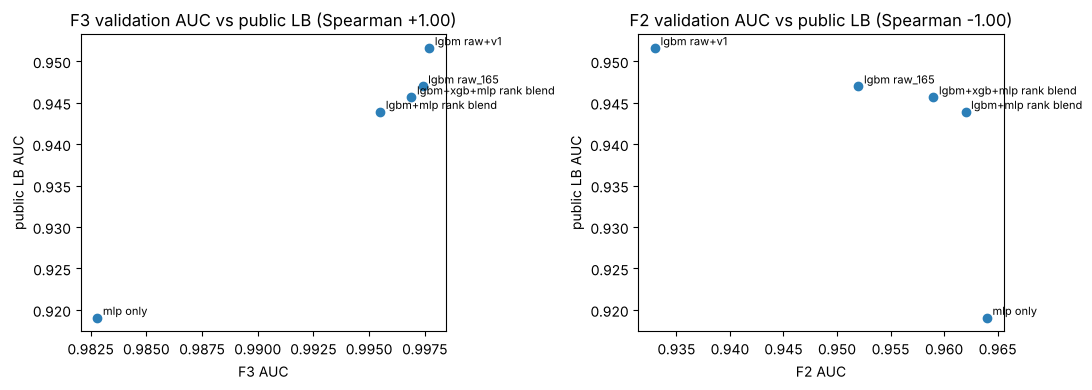

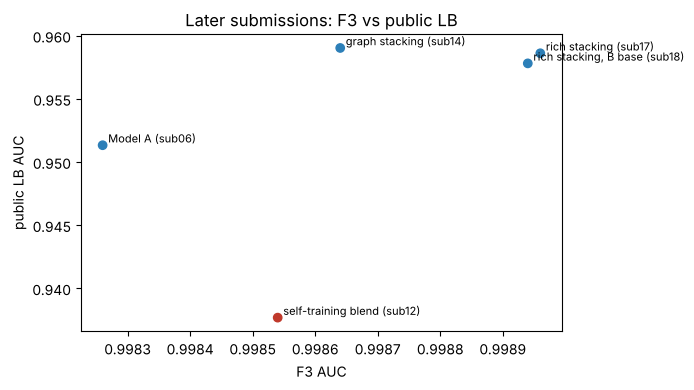

In [ ]:
# validation scores recorded during the competition vs the public leaderboard
val_vs_lb = pd.DataFrame([
    # submission,                         F3 (recent),  F2 (hard),  public LB
    ("lgbm raw_165",                        0.9974,      0.952,      0.94699),
    ("lgbm raw+v1",                         0.9977,      0.933,      0.95161),
    ("lgbm+xgb+mlp rank blend",             0.9969,      0.959,      0.94567),
    ("lgbm+mlp rank blend",                 0.9955,      0.962,      0.94392),
    ("mlp only",                            0.9828,      0.964,      0.91907),
], columns=["submission", "F3", "F2", "public"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, fold in zip(axes, ["F3", "F2"]):
    ax.scatter(val_vs_lb[fold], val_vs_lb["public"], color="#2c7fb8")
    for _, r in val_vs_lb.iterrows():
        ax.annotate(r["submission"], (r[fold], r["public"]), fontsize=8, xytext=(4, 2), textcoords="offset points")
    rho = spearmanr(val_vs_lb[fold], val_vs_lb["public"])[0]
    ax.set_title(f"{fold} validation AUC vs public LB (Spearman {rho:+.2f})")
    ax.set_xlabel(f"{fold} AUC"); ax.set_ylabel("public LB AUC")
fig.tight_layout(); plt.show()

# later submissions on F3 (single-model F3 scores, 2-3 seeds)
later = pd.DataFrame([
    ("Model A (sub06)",                 0.99826, 0.95133, "#2c7fb8"),
    ("self-training blend (sub12)",     0.99854, 0.93768, "#c0392b"),
    ("graph stacking (sub14)",          0.99864, 0.95903, "#2c7fb8"),
    ("rich stacking (sub17)",           0.99896, 0.95861, "#2c7fb8"),
    ("rich stacking, B base (sub18)",   0.99894, 0.95781, "#2c7fb8"),
], columns=["submission", "F3", "public", "colour"])
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(later.F3, later.public, c=later.colour)
for _, r in later.iterrows():
    ax.annotate(r["submission"], (r.F3, r.public), fontsize=8, xytext=(4, 2), textcoords="offset points")
ax.set_xlabel("F3 AUC"); ax.set_ylabel("public LB AUC"); ax.set_title("Later submissions: F3 vs public LB")
fig.tight_layout(); plt.show()

## 5. Feature-set ablation (3 folds × 3 seeds)

In [12]:
if RUN_ABLATION:
    rows = {}
    for name, cols in FEATURE_SETS.items():
        t0 = time.time()
        rows[name] = temporal_auc(cols)
        print(f"{name:18s} {rows[name]}  ({time.time() - t0:.0f}s)")
    ablation = pd.DataFrame(rows).T
    ablation["mean"] = ablation.mean(axis=1)
    display(ablation.round(5))
else:
    print("skipped (RUN_ABLATION = False)")

raw_165            {'F1': np.float64(0.9939544039723579), 'F2': np.float64(0.952037265793992), 'F3': np.float64(0.9973778282771343)}  (55s)


raw+v1 (Model B)   {'F1': np.float64(0.9941991567558647), 'F2': np.float64(0.9347568796803108), 'F3': np.float64(0.9977414678561525)}  (128s)


raw+v2 (Model A)   {'F1': np.float64(0.9946990457742994), 'F2': np.float64(0.9398791648866882), 'F3': np.float64(0.9980645188229228)}  (120s)


,F1,F2,F3,mean
raw_165,0.99395,0.95204,0.99738,0.98112
raw+v1 (Model B),0.99420,0.93476,0.99774,0.97557
raw+v2 (Model A),0.99470,0.93988,0.99806,0.97755


on F3, v1 and v2 both beat raw features, and v2 is best, but on F2, both graph-feature sets look worse

## 6. Single-stage models
the best models without stacking (public LB: Model A 0.95133, Model B 0.95161, rank-blend of the two 0.95331), kept as reference points and for feature-importance and post-43 analysis

In [ ]:
def fit_lgb(df, cols, seed, n_estimators=1000, sample_weight=None):
    """One LightGBM model with the shared settings."""
    m = lgb.LGBMClassifier(**{**LGB_PARAMS, "n_estimators": n_estimators, "random_state": seed})
    return m.fit(df[cols], df.label, sample_weight=sample_weight)

def fit_predict(cols, n_estimators, seeds):
    """Train on all labelled steps 1-35 and return the seed-averaged test probability."""
    preds = []
    for s in seeds:
        m = fit_lgb(lab, cols, s, n_estimators)
        preds.append(m.predict_proba(test_full[cols])[:, 1])
    return np.mean(preds, axis=0), m

t0 = time.time()
pred_A, model_A = fit_predict(FEATURE_SETS["raw+v2 (Model A)"], n_estimators=1000, seeds=range(5))
pred_B, model_B = fit_predict(FEATURE_SETS["raw+v1 (Model B)"], n_estimators=500, seeds=[SEED])
print(f"trained in {time.time() - t0:.0f}s | Spearman(A, B) on test = {spearmanr(pred_A, pred_B)[0]:.3f}")

# rank-average
rank01 = lambda v: rankdata(v) / len(v)

trained in 206s | Spearman(A, B) on test = 0.894


In [ ]:
def write_submission(pred, fname):
    sub = pd.DataFrame({"index": test_full["index"].values, "target": pred})
    assert len(sub) == len(sample_sub) and set(sub["index"]) == set(sample_sub["index"])
    assert sub.target.between(0, 1).all() and sub.target.notna().all()
    sub = sub.set_index("index").loc[sample_sub["index"]].reset_index()
    sub.to_csv(SUB_DIR / fname, index=False)
    print("wrote", SUB_DIR / fname, sub.shape)

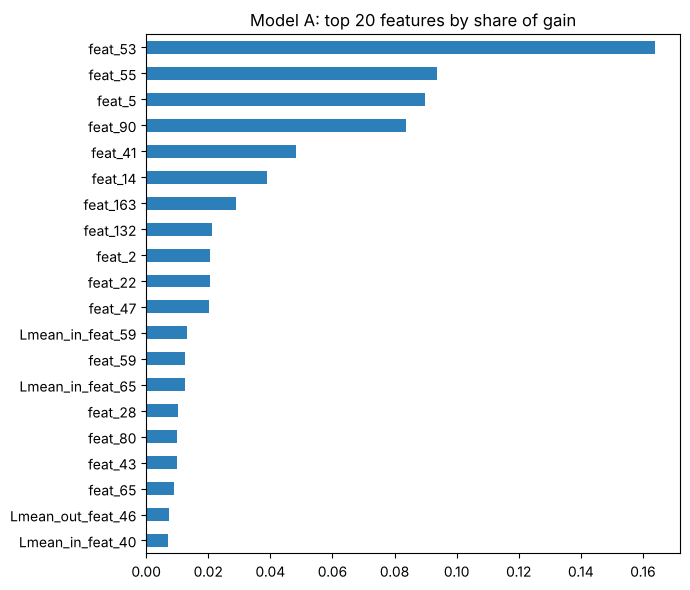

share of gain from v2 graph features: 0.127


In [ ]:
# top features of model A (last seed)
imp = pd.Series(model_A.booster_.feature_importance("gain"), index=FEATURE_SETS["raw+v2 (Model A)"])
imp = (imp / imp.sum()).sort_values(ascending=False)
ax = imp.head(20).iloc[::-1].plot.barh(figsize=(7, 6), color="#2c7fb8")
ax.set_title("Model A: top 20 features by share of gain"); plt.tight_layout(); plt.show()
print("share of gain from v2 graph features:", round(imp[CNT + LMEAN].sum(), 3))

## 7. Graph stacking

### 7.1 Idea
linked transactions tend to share labels, so in the labelled training graph, an illicit transaction's labelled neighbours are 54% illicit, against 2% for a licit transaction. 
neighbour labels cannot be used, because test neighbours are unlabelled, but neighbour predicted scores can:

1. stage 1: Model A scores every labelled transaction
   - train: out-of-fold, using GroupKFold with time steps as groups (5 folds). Each training transaction is scored by a model that doesnt see its time step, so it doesnt see that transaction's own label or its neighbours' labels
   - test: Model A trained on all labelled steps 1–35
2. neighbour-score features: for every transaction: mean and max of stage-1 scores over its labelled senders, its labelled receivers, and all labelled neighbours, and the sum. Only labelled neighbours have scores in the test period, so only labelled neighbours are also used in train
3. Stage 2: LightGBM on Model A's features plus the neighbour-score features

this is a learned version of label propagation: stage 2 decides how much to trust neighbour scores. 
simple fixed-weight smoothing of predictions over the graph made F3 worse, but the learned version made it better

rich variant adds the standard deviation of neighbour scores, the number of neighbours scoring above 0.5, and the mean score over 2-hop labelled neighbours

In [ ]:
# homophily check on the labelled training graph
y_by_id = lab.set_index("txId")["label"]
e_ll = edges[edges.txId1.isin(y_by_id.index) & edges.txId2.isin(y_by_id.index)]
pairs = pd.concat([
    pd.DataFrame({"node": e_ll.txId1.values, "nbr_label": y_by_id.reindex(e_ll.txId2).values}),
    pd.DataFrame({"node": e_ll.txId2.values, "nbr_label": y_by_id.reindex(e_ll.txId1).values}),
])
share = pairs.groupby("node")["nbr_label"].mean().rename("share_of_labelled_neighbours_illicit")
lab[["txId", "label"]].join(share, on="txId").groupby("label")["share_of_labelled_neighbours_illicit"].mean().round(3)

label
0    0.022
1    0.542
Name: share_of_labelled_neighbours_illicit, dtype: float64

In [17]:
from sklearn.model_selection import GroupKFold
import scipy.sparse as sp

def oof_and_apply(tr, ap, cols, seed, k=5):
    """Out-of-fold predictions on `tr` (grouped by time step) and full-model predictions on `ap`."""
    oof = np.zeros(len(tr))
    for fit_idx, pred_idx in GroupKFold(k).split(tr, groups=tr.time_step):
        m = fit_lgb(tr.iloc[fit_idx], cols, seed)
        oof[pred_idx] = m.predict_proba(tr.iloc[pred_idx][cols])[:, 1]
    return oof, fit_lgb(tr, cols, seed).predict_proba(ap[cols])[:, 1]

def neighbour_score_features(ids, p, rich=False):
    """Aggregate stage-1 scores `p` (indexed by `ids`) over each node's labelled neighbours."""
    s = pd.Series(p, index=ids)
    e = edges[edges.txId1.isin(s.index) & edges.txId2.isin(s.index)]
    out = pd.DataFrame(index=ids)
    for nm, (tgt, src) in {"in": ("txId2", "txId1"), "out": ("txId1", "txId2")}.items():
        g = pd.Series(s.reindex(e[src]).values, index=e[tgt].values).groupby(level=0)
        out[f"pn_{nm}_mean"], out[f"pn_{nm}_max"] = g.mean(), g.max()
    all_p = pd.concat([pd.Series(s.reindex(e.txId1).values, index=e.txId2.values),
                       pd.Series(s.reindex(e.txId2).values, index=e.txId1.values)])
    g = all_p.groupby(level=0)
    out["pn_mean"], out["pn_max"], out["pn_sum"] = g.mean(), g.max(), g.sum()
    if rich:
        out["pn_std"] = g.std()
        out["pn_n_hi"] = (all_p > 0.5).groupby(level=0).sum()
        # mean score over 2-hop labelled neighbours (undirected), excluding the node itself
        pos = pd.Series(np.arange(len(s)), index=s.index)
        a, b, n = pos[e.txId1].values, pos[e.txId2].values, len(s)
        S = sp.coo_matrix((np.ones(len(a)), (a, b)), shape=(n, n)).tocsr(); S = S + S.T
        S2 = (S @ S).tocsr(); S2.setdiag(0); S2.eliminate_zeros()
        d2 = np.asarray(S2.sum(1)).ravel()
        out["pn_2hop_mean"] = np.where(d2 > 0, (S2 @ s.values) / np.maximum(d2, 1), np.nan)
    return out

import xgboost as xgb
XGB_PARAMS = dict(n_estimators=800, learning_rate=0.03, max_depth=6, subsample=0.8,
                  colsample_bytree=0.5, n_jobs=-1, tree_method="hist")

def stacked_predict(tr, ap, stage1_cols, stage2_base_cols, seed, rich=False, learner="lgb", lgb_kw=None):
    """Full two-stage pipeline: returns stage-2 predictions for `ap` (and stage-1 predictions for reference).

    learner: 'lgb' (default) or 'xgb' for the second stage; lgb_kw overrides LightGBM settings for stage 2.
    """
    oof, p_ap = oof_and_apply(tr, ap, stage1_cols, seed)
    F = neighbour_score_features(np.r_[tr.txId.values, ap.txId.values], np.r_[oof, p_ap], rich=rich)
    tr2, ap2 = tr.join(F, on="txId"), ap.join(F, on="txId")
    cols2 = stage2_base_cols + list(F.columns)
    if learner == "xgb":
        m = xgb.XGBClassifier(**XGB_PARAMS, random_state=seed).fit(tr2[cols2], tr2.label)
    elif lgb_kw:
        m = lgb.LGBMClassifier(**{**LGB_PARAMS, "n_estimators": 1000, **lgb_kw, "random_state": seed}).fit(tr2[cols2], tr2.label)
    else:
        m = fit_lgb(tr2, cols2, seed)
    return m.predict_proba(ap2[cols2])[:, 1], p_ap

### 7.2 Validation on F3 (train steps 1–28, validate 29–35)
whole two-stage pipeline is rerun inside the fold, so stage-1 out-of-fold scores only use steps 1–28

In [18]:
COLS_A = FEATURE_SETS["raw+v2 (Model A)"]
COLS_B = FEATURE_SETS["raw+v1 (Model B)"]

if RUN_STACK_VALIDATION:
    tr_f3, va_f3 = lab[lab.time_step <= 28], lab[lab.time_step.between(29, 35)]
    rows = []
    for s in (1, 2):
        t0 = time.time()
        p2, p1 = stacked_predict(tr_f3, va_f3, COLS_A, COLS_A, seed=s)
        rows.append((s, roc_auc_score(va_f3.label, p1), roc_auc_score(va_f3.label, p2)))
        print(f"seed {s}: {time.time() - t0:.0f}s")
    display(pd.DataFrame(rows, columns=["seed", "Model A (stage 1)", "graph stacking (stage 2)"]).set_index("seed").round(5))
else:
    print("skipped (RUN_STACK_VALIDATION = False)")

seed 1: 214s


seed 2: 206s


,Model A (stage 1),graph stacking (stage 2)
seed,,
1,0.99826,0.99866
2,0.99832,0.99863


### 7.3 Graph stacking on Model A: sub14 (public 0.95903, final pick 2)

In [19]:
t0 = time.time()
stack_preds = [stacked_predict(lab, test_full, COLS_A, COLS_A, seed=s)[0] for s in STACK_SEEDS]
pred_stack = np.mean(stack_preds, axis=0)
print(f"built in {time.time() - t0:.0f}s | Spearman(stacked, Model A) on test = {spearmanr(pred_stack, pred_A)[0]:.3f}")
write_submission(pred_stack, "final_sub14_graphstack.csv")

built in 672s | Spearman(stacked, Model A) on test = 0.955
wrote submissions/final_sub14_graphstack.csv (15329, 2)


### 7.4 Final pick 1: rank-average of 8 stacked models (sub23, public 0.95985)
sub14 plus seven more stacked models, where each one changes one ingredient so that its errors overlap less with the others
all seven use the rich neighbour-score features

| Member | Stage-1 scores from | Stage-2 learner | Stage-2 base features |
|---|---|---|---|
| `sub14` (7.3) | Model A | LightGBM | Model A's (basic neighbour scores) |
| `rich_A` | Model A | LightGBM | Model A's |
| `rich_B` | Model A | LightGBM | Model B's |
| `xgb2` | Model A | XGBoost | Model A's |
| `Bpipe` | Model B | LightGBM | Model B's |
| `raw2` | Model A | LightGBM | raw 165 only |
| `xgbB` | Model B | XGBoost | Model B's |
| `lgbAlt` | Model A | LightGBM (63 leaves, 30% column sampling, min 40 rows per leaf) | Model A's |

In [ ]:
MEMBERS = {
    "rich_A": dict(stage1_cols=COLS_A, stage2_base_cols=COLS_A),
    "rich_B": dict(stage1_cols=COLS_A, stage2_base_cols=COLS_B),
    "xgb2":   dict(stage1_cols=COLS_A, stage2_base_cols=COLS_A, learner="xgb"),
    "Bpipe":  dict(stage1_cols=COLS_B, stage2_base_cols=COLS_B),
    "raw2":   dict(stage1_cols=COLS_A, stage2_base_cols=FEATS),
    "xgbB":   dict(stage1_cols=COLS_B, stage2_base_cols=COLS_B, learner="xgb"),
    "lgbAlt": dict(stage1_cols=COLS_A, stage2_base_cols=COLS_A,
                   lgb_kw=dict(num_leaves=63, colsample_bytree=0.3, min_child_samples=40)),
}
members = {"sub14": pred_stack}
for name, kw in MEMBERS.items():
    t0 = time.time()
    members[name] = np.mean([stacked_predict(lab, test_full, seed=s, rich=True, **kw)[0] for s in STACK_SEEDS], axis=0)
    print(f"{name}: {time.time() - t0:.0f}s")

# spearman rank correlation on test to see how different the members are
display(pd.DataFrame(members).corr(method="spearman").round(3))

# rank-average
pred_sub23 = np.mean([rank01(v) for v in members.values()], axis=0)
write_submission(pred_sub23, "final_sub23_stack_ensemble8.csv")

rich_A: 679s


rich_B: 673s


xgb2: 683s


Bpipe: 643s


raw2: 596s


xgbB: 648s


lgbAlt: 630s


,sub14,rich_A,rich_B,xgb2,Bpipe,raw2,xgbB,lgbAlt
sub14,1.000,0.989,0.934,0.956,0.935,0.956,0.885,0.972
rich_A,0.989,1.000,0.950,0.965,0.950,0.965,0.904,0.977
rich_B,0.934,0.950,1.000,0.943,0.994,0.956,0.966,0.917
xgb2,0.956,0.965,0.943,1.000,0.940,0.947,0.946,0.960
Bpipe,0.935,0.950,0.994,0.940,1.000,0.953,0.964,0.916
raw2,0.956,0.965,0.956,0.947,0.953,1.000,0.917,0.940
xgbB,0.885,0.904,0.966,0.946,0.964,0.917,1.000,0.882
lgbAlt,0.972,0.977,0.917,0.960,0.916,0.940,0.882,1.000


wrote submissions/final_sub23_stack_ensemble8.csv (15329, 2)


## 8. Post-step-43 analysis
in the original Elliptic data, a large dark market shut down around step 43. 
published work on the same temporal split reports the illicit rate falling from about 11% at step 42 to 1.8% at step 43 and 0.3% by step 46
final model test predictions show the same break

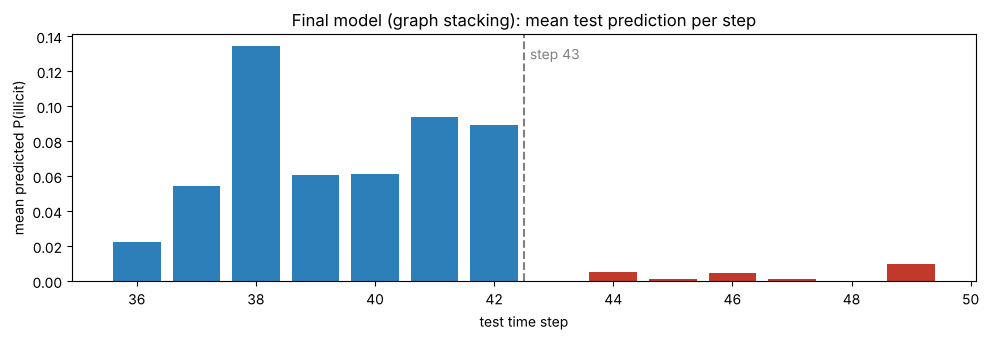

time_step,36,37,38,39,40,41,42,43,44,45,46,47,48,49
n,1708.000,498.000,756.000,1183.000,1211.000,1132.000,2154.000,1370.0,1591.000,1221.000,712.000,846.000,471.0,476.00
mean_pred,0.022,0.054,0.134,0.061,0.061,0.094,0.089,0.0,0.005,0.001,0.004,0.001,0.0,0.01
n_above_0_5,39.000,27.000,101.000,73.000,75.000,107.000,191.000,0.0,9.000,2.000,2.000,1.000,0.0,3.00


In [21]:
t = test_full[["time_step"]].assign(p=pred_stack)
post43 = t.groupby("time_step")["p"].agg(n="size", mean_pred="mean", n_above_0_5=lambda x: int((x > 0.5).sum()))
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(post43.index, post43["mean_pred"], color=np.where(post43.index >= 43, "#c0392b", "#2c7fb8"))
ax.axvline(42.5, ls="--", color="grey"); ax.text(42.6, ax.get_ylim()[1] * 0.9, "step 43", color="grey")
ax.set_xlabel("test time step"); ax.set_ylabel("mean predicted P(illicit)")
ax.set_title("Final model (graph stacking): mean test prediction per step"); plt.tight_layout(); plt.show()
post43.T.round(3)

tested whether rescaling post-43 scores would help, since AUC is computed over all steps pooled together.
three probes (lifting post-43 scores to the pre-43 distribution, within-step ranks, and a 50/50 mix) lowered the public score. that fits the published finding that there are very few illicit transactions left after step 43 to recover, so lifting those scores mostly promotes licit transactions

## 9. Experiment log

In [22]:
log = pd.DataFrame([
    # (file, description, F3 validation, public LB)
    ("lgbm_all_165",             "LightGBM, raw 165 features (baseline)",                       0.9974,  0.94699),
    ("lgbm_all_165_deg_nbr",     "LightGBM, raw + v1 graph features (= Model B)",               0.9977,  0.95161),
    ("sub03_lgb_mlp_rank",       "rank blend LightGBM + MLP",                                   0.9955,  0.94392),
    ("sub04_mlp_5seed",          "MLP (quantile-normalised inputs), 5 seeds",                   0.9828,  0.91907),
    ("sub05_lgb_xgb_mlp_rank",   "rank blend LightGBM + XGBoost + MLP",                         0.9969,  0.94567),
    ("sub06_lgb_labnbr",         "LightGBM, raw + v2 graph features (= Model A)",               0.9983,  0.95133),
    ("sub07_blend_labnbr_oldnbr","rank blend Model A + Model B",                                np.nan,  0.95331),
    ("sub08_lgb_labnbr_plus_old","LightGBM, raw + v1 + v2",                                     0.9981,  0.95120),
    ("probe1_post43_quantilemap","sub07, post-43 steps rescaled to pre-43 distribution",        np.nan,  0.94344),
    ("probe2_withinstep_rank",   "sub07, within-step ranks",                                    np.nan,  0.93375),
    ("probe3_half_half",         "sub07, 50/50 global + within-step rank",                      np.nan,  0.94655),
    ("sub09_ens5_rank",          "rank blend of 5 LightGBM/XGBoost models",                     np.nan,  0.95245),
    ("sub10_ens3_graph_rank",    "rank blend Model A + Model B + XGBoost(v2)",                  np.nan,  0.95283),
    ("sub12_selftrain_blend",    "sub07 recipe with one round of self-training on test",        0.99854, 0.93768),
    ("sub14_graphstack",         "graph stacking on Model A  [FINAL PICK 2]",                   0.99864, 0.95903),
    ("sub15_blend_A_B_stack",    "rank blend Model A + Model B + sub14",                        np.nan,  0.95561),
    ("sub16_blend_A_B_bagged",   "sub07 with Model B bagged over 5 seeds / 1000 trees",         np.nan,  0.95258),
    ("sub17_stack_rich",         "graph stacking, rich neighbour-score features",               0.99896, 0.95861),
    ("sub18_stack_rich_Bbase",   "rich stacking, stage 2 on Model B's features",                0.99894, 0.95781),
    ("sub19_blend_stack_rich",   "rank blend sub17 + sub18",                                    np.nan,  0.95892),
    ("sub20_blend_stack_14_17_18","rank blend sub14 + sub17 + sub18",                           np.nan,  0.95931),
    ("sub21_stack_ens6",         "rank blend of 6 stacked models",                              np.nan,  0.95975),
    ("sub22_stack_ens5",         "sub21 without Bpipe",                                         np.nan,  0.95938),
    ("sub23_stack_ens8",         "sub21 + xgbB + lgbAlt (8 stacked models)  [FINAL PICK 1]",    np.nan,  0.95985),
], columns=["file", "description", "F3_val_auc", "public_lb"])
log

,file,description,F3_val_auc,public_lb
0,lgbm_all_165,"LightGBM, raw 165 features (baseline)",0.99740,0.94699
1,lgbm_all_165_deg_nbr,"LightGBM, raw + v1 graph features (= Model B)",0.99770,0.95161
2,sub03_lgb_mlp_rank,rank blend LightGBM + MLP,0.99550,0.94392
3,sub04_mlp_5seed,"MLP (quantile-normalised inputs), 5 seeds",0.98280,0.91907
4,sub05_lgb_xgb_mlp_rank,rank blend LightGBM + XGBoost + MLP,0.99690,0.94567
5,sub06_lgb_labnbr,"LightGBM, raw + v2 graph features (= Model A)",0.99830,0.95133
6,sub07_blend_labnbr_oldnbr,rank blend Model A + Model B,NaN,0.95331
7,sub08_lgb_labnbr_plus_old,"LightGBM, raw + v1 + v2",0.99810,0.95120
8,probe1_post43_quantilemap,"sub07, post-43 steps rescaled to pre-43 distri...",NaN,0.94344
9,probe2_withinstep_rank,"sub07, within-step ranks",NaN,0.93375


self-training failed on the leaderboard because it pseudo-labelled 14,691 of 15,329 test transactions as licit, including new-pattern illicit transactions the model was already missing, and then retrained on those labels

data leakage was deliberately not used. the txId values are the original Elliptic transaction IDs, so test labels could be looked up in the public Elliptic dataset. 
row order within a time step also carries weak signal